load the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path("..")
det = pd.read_csv(ROOT / "data/processed/detection/splits.csv")
rec = pd.read_csv(ROOT / "data/processed/recognition/splits.csv", dtype={"text": str})
print(det.shape, rec.shape)

(832, 6) (888, 3)


images sizes and boxes

In [2]:
img_dir = ROOT / "data/raw/detection/images"
det[["img_w", "img_h"]] = [Image.open(img_dir / i).size for i in det.img_id]
det["box_w"] = (det.xmax - det.xmin) / det.img_w
det["box_h"] = (det.ymax - det.ymin) / det.img_h
det["box_area_%"] = det.box_w * det.box_h * 100
det["xc"] = (det.xmin + det.xmax) / 2 / det.img_w
det["yc"] = (det.ymin + det.ymax) / 2 / det.img_h

print(det[["img_w", "img_h", "box_area_%"]].describe().round(2))

        img_w   img_h  box_area_%
count  832.00  832.00      832.00
mean   611.53  513.70        1.91
std    202.69   52.46        1.06
min    241.00  239.00        0.36
25%    410.00  477.00        1.24
50%    729.00  547.00        1.73
75%    802.75  547.00        2.30
max    850.00  547.00       11.34


detection charts

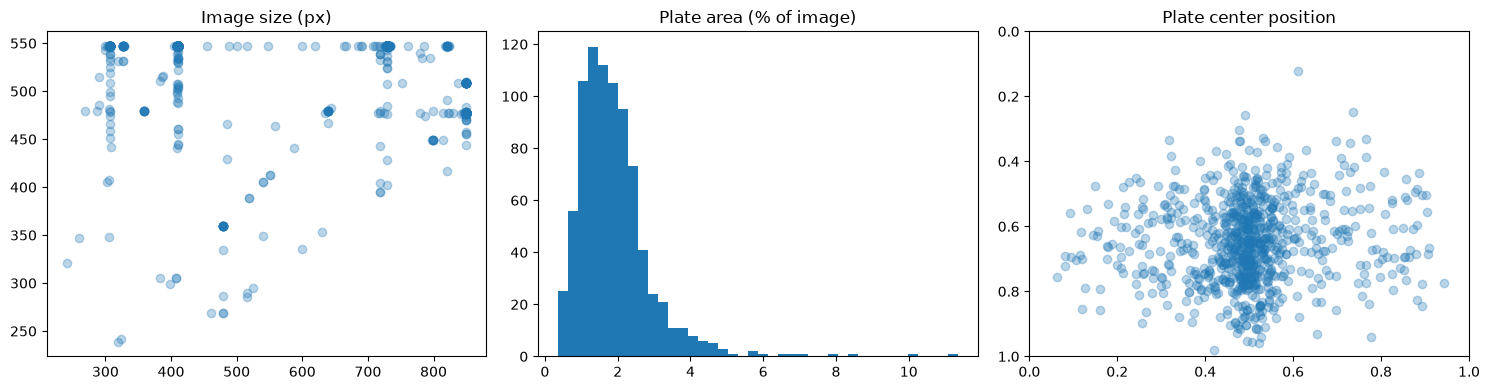

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(det.img_w, det.img_h, alpha=0.3); ax[0].set_title("Image size (px)")
ax[1].hist(det["box_area_%"], bins=40); ax[1].set_title("Plate area (% of image)")
ax[2].scatter(det.xc, det.yc, alpha=0.3); ax[2].invert_yaxis()
ax[2].set_title("Plate center position"); ax[2].set_xlim(0, 1); ax[2].set_ylim(1, 0)
plt.tight_layout(); plt.show()

OCR, text length and format

In [4]:
rec["length"] = rec.text.str.len()
rec["format"] = rec.text.str.contains("T").map({True: "T (تونس)", False: "N (ن.ت)"})
print(rec.format.value_counts(), "\n")
print(rec.length.value_counts().sort_index())
print("\nImages per plate (top 5):\n", rec.text.value_counts().head())

format
T (تونس)    883
N (ن.ت)       5
Name: count, dtype: int64 

length
5      1
6     28
7    323
8    536
Name: count, dtype: int64

Images per plate (top 5):
 text
106T2131    8
94T8974     7
179T7121    6
121T237     5
107T5823    5
Name: count, dtype: int64


character frequency

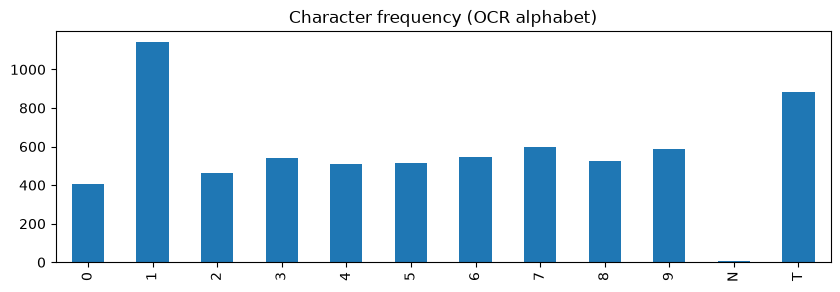

Alphabet: 0123456789NT


In [5]:
chars = pd.Series(list("".join(rec.text))).value_counts().sort_index()
chars.plot.bar(figsize=(10, 3), title="Character frequency (OCR alphabet)")
plt.show()
print("Alphabet:", "".join(chars.index))